# 1. Base de datos

## 1.1 Problema de investigación

Un banco portugués realizó campañas de telemercadeo para ofrecer depósitos a término a sus clientes. Cada llamada consume tiempo de un asesor y la mayoría de los clientes contactados no suscribe, por lo que decidir a quién llamar primero es primordial para la eficiencia de la campaña. En ese sentido, el problema es de **clasificación binaria**: predecir, **con la información disponible antes de realizar la llamada**, si el cliente suscribirá el depósito (`y = yes`) o no (`y = no`).

**Pregunta de investigación.** En el Entregable 2 la pregunta se limitó al modelo base; las preguntas de este entregable, que amplían la comparación a 165 combinaciones, a la eficiencia de los optimizadores y a una rama de regresión, están en la sección 4.1.

## 1.2 Justificación de la selección

- **Tamaño suficiente:** más de 40 000 registros (el mínimo exigido es 20 000) y 20 predictoras de tipos mixtos (numéricas, categóricas nominales y ordinales, indicadores macroeconómicos).
- **Desbalance real de clases:** la clase positiva es minoritaria, lo que obliga a evaluar con métricas que no dependan de la clase mayoritaria (sección 3.1).
- **Riesgos de fuga documentados:** la variable `duration` solo se conoce después de la llamada y las filas están ordenadas en el tiempo; esto hace que la auditoría de fuga (secciones 3.5 y 3.6) sea un componente central y no un trámite.
- **Problemas de calidad reales:** faltantes codificados como `unknown`, códigos especiales (`pdays = 999`) y duplicados, útiles para aplicar el protocolo de calidad del enunciado.
- **Uso legítimo:** datos públicos con licencia abierta y un artículo de referencia revisado por pares.

## 1.3 Fuente de los datos y licencia

- **Repositorio:** UCI Machine Learning Repository, conjunto *Bank Marketing* (identificador 222): <https://archive.ics.uci.edu/dataset/222/bank+marketing>, DOI <https://doi.org/10.24432/C5K306>.
- **Archivo usado:** `bank-additional-full.csv` (versión con cinco indicadores sociales y económicos), incluido en la carpeta `data/` de esta entrega.
- **Licencia:** Creative Commons Attribution 4.0 International (CC BY 4.0), que permite el uso con atribución.
- **Origen:** según la documentación del repositorio, los registros provienen de campañas de una institución bancaria portuguesa y los indicadores macroeconómicos fueron publicados por el Banco de Portugal. El archivo trae las filas ordenadas por fecha, de mayo de 2008 a noviembre de 2010.
- **Cita del artículo de referencia:** Moro, S., Cortez, P. y Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. *Decision Support Systems, 62*, 22–31. <https://doi.org/10.1016/j.dss.2014.03.001>

In [2]:
RUTA_DATOS = Path("data") / "bank-additional-full.csv"
df = pd.read_csv(RUTA_DATOS, sep=";")

OBJETIVO = "y"
NUMERICAS = ["age", "duration", "campaign", "pdays", "previous",
             "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
CATEGORICAS = ["job", "marital", "education", "default", "housing", "loan",
               "contact", "month", "day_of_week", "poutcome"]
MACRO = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
assert set(NUMERICAS + CATEGORICAS + [OBJETIVO]) == set(df.columns)

print(f"Archivo: {RUTA_DATOS.as_posix()} · {num(df.shape[0])} filas × {df.shape[1]} columnas")
display(df.head())

Archivo: data/bank-additional-full.csv · 41 188 filas × 21 columnas


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 1.4 Diccionario de variables

El significado de cada variable proviene del archivo de documentación del repositorio (`bank-additional-names.txt`); el tipo en el archivo y el número de valores distintos se calculan sobre los datos.

In [3]:
diccionario = pd.DataFrame([
    ("age", "Cliente", "Numérica discreta", "Años", "Edad del cliente"),
    ("job", "Cliente", "Categórica nominal", "12 categorías, incluye unknown", "Tipo de ocupación"),
    ("marital", "Cliente", "Categórica nominal", "divorced (incluye viudos), married, single, unknown", "Estado civil"),
    ("education", "Cliente", "Categórica ordinal", "8 niveles, incluye unknown", "Nivel educativo"),
    ("default", "Cliente", "Categórica", "no, yes, unknown", "¿Tiene crédito en mora?"),
    ("housing", "Cliente", "Categórica", "no, yes, unknown", "¿Tiene crédito de vivienda?"),
    ("loan", "Cliente", "Categórica", "no, yes, unknown", "¿Tiene crédito personal?"),
    ("contact", "Último contacto", "Categórica binaria", "cellular, telephone", "Canal del contacto"),
    ("month", "Último contacto", "Categórica cíclica", "Mes, sin año", "Mes del último contacto"),
    ("day_of_week", "Último contacto", "Categórica cíclica", "Lunes a viernes", "Día de la semana del último contacto"),
    ("duration", "Último contacto", "Numérica discreta", "Segundos",
     "Duración del último contacto; solo se conoce al terminar la llamada"),
    ("campaign", "Campaña actual", "Numérica discreta (conteo)", "Número de contactos",
     "Contactos hechos a este cliente en esta campaña, incluido el último"),
    ("pdays", "Campañas anteriores", "Numérica discreta con código", "Días; 999 = sin contacto previo",
     "Días desde el último contacto de una campaña anterior"),
    ("previous", "Campañas anteriores", "Numérica discreta (conteo)", "Número de contactos",
     "Contactos hechos a este cliente antes de esta campaña"),
    ("poutcome", "Campañas anteriores", "Categórica nominal", "failure, nonexistent, success",
     "Resultado de la campaña anterior"),
    ("emp.var.rate", "Contexto macroeconómico", "Numérica continua", "Tasa; indicador trimestral",
     "Tasa de variación del empleo"),
    ("cons.price.idx", "Contexto macroeconómico", "Numérica continua", "Índice; indicador mensual",
     "Índice de precios al consumidor"),
    ("cons.conf.idx", "Contexto macroeconómico", "Numérica continua", "Índice; indicador mensual",
     "Índice de confianza del consumidor"),
    ("euribor3m", "Contexto macroeconómico", "Numérica continua", "Tasa en %; indicador diario",
     "Tasa Euribor a tres meses"),
    ("nr.employed", "Contexto macroeconómico", "Numérica continua",
     "Número de empleados; indicador trimestral (la fuente no documenta la escala)", "Número de empleados"),
    ("y", "Objetivo", "Categórica binaria", "yes, no", "¿El cliente suscribió un depósito a término?"),
], columns=["Variable", "Grupo", "Tipo", "Unidad o valores", "Significado"])
diccionario["Tipo en el archivo"] = diccionario["Variable"].map(lambda c: str(df[c].dtype))
diccionario["Valores distintos"] = diccionario["Variable"].map(lambda c: df[c].nunique())
tabla(diccionario, indice=False)

conteo_grupos = diccionario["Grupo"].value_counts()
interpretar(
    f"El archivo tiene {len(NUMERICAS)} predictoras numéricas y {len(CATEGORICAS)} categóricas, más la variable "
    f"objetivo `y`. Se agrupan en atributos del cliente ({conteo_grupos['Cliente']}), del último contacto "
    f"({conteo_grupos['Último contacto']}), de la campaña actual y de las anteriores "
    f"({conteo_grupos['Campaña actual'] + conteo_grupos['Campañas anteriores']}) y de contexto macroeconómico "
    f"({conteo_grupos['Contexto macroeconómico']}). Las categóricas tienen entre "
    f"{min(df[c].nunique() for c in CATEGORICAS)} y {max(df[c].nunique() for c in CATEGORICAS)} valores distintos.",
    "Así mismo, los indicadores macroeconómicos no describen al cliente sino el momento de la llamada; por eso pueden "
    "actuar como marcadores del periodo. `duration` describe la llamada ya realizada y no estará disponible "
    "cuando se quiera predecir.",
    "Por tal motivo, se opta por tratar `month` y `day_of_week` como categóricas (no hay año), `education` como "
    "nominal en el modelo base (su categoría `unknown` no tiene un lugar en el orden) y auditar `duration` y las "
    "variables macroeconómicas en la sección 3.5.")

Variable,Grupo,Tipo,Unidad o valores,Significado,Tipo en el archivo,Valores distintos
age,Cliente,Numérica discreta,Años,Edad del cliente,int64,78
job,Cliente,Categórica nominal,"12 categorías, incluye unknown",Tipo de ocupación,str,12
marital,Cliente,Categórica nominal,"divorced (incluye viudos), married, single, unknown",Estado civil,str,4
education,Cliente,Categórica ordinal,"8 niveles, incluye unknown",Nivel educativo,str,8
default,Cliente,Categórica,"no, yes, unknown",¿Tiene crédito en mora?,str,3
housing,Cliente,Categórica,"no, yes, unknown",¿Tiene crédito de vivienda?,str,3
loan,Cliente,Categórica,"no, yes, unknown",¿Tiene crédito personal?,str,3
contact,Último contacto,Categórica binaria,"cellular, telephone",Canal del contacto,str,2
month,Último contacto,Categórica cíclica,"Mes, sin año",Mes del último contacto,str,10
day_of_week,Último contacto,Categórica cíclica,Lunes a viernes,Día de la semana del último contacto,str,5


**Interpretación.** El archivo tiene 10 predictoras numéricas y 10 categóricas, más la variable objetivo `y`. Se agrupan en atributos del cliente (7), del último contacto (4), de la campaña actual y de las anteriores (4) y de contexto macroeconómico (5). Las categóricas tienen entre 2 y 12 valores distintos.

Así mismo, los indicadores macroeconómicos no describen al cliente sino el momento de la llamada; por eso pueden actuar como marcadores del periodo. `duration` describe la llamada ya realizada y no estará disponible cuando se quiera predecir.

Por tal motivo, se opta por tratar `month` y `day_of_week` como categóricas (no hay año), `education` como nominal en el modelo base (su categoría `unknown` no tiene un lugar en el orden) y auditar `duration` y las variables macroeconómicas en la sección 3.5.

## 1.5 Estructura de los datos

- **Unidad de observación:** un contacto telefónico de una campaña con un cliente; cada fila guarda los atributos del cliente, los del último contacto de la campaña y el resultado (`y`).
- **Nivel de agregación:** individual (cliente-contacto). Los cinco indicadores macroeconómicos están agregados a nivel nacional y se repiten para todos los contactos del mismo periodo.
- **Tipo de datos:** transversal con **orden temporal implícito**. No hay una columna de fecha; solo se conocen el mes (`month`) y el día de la semana (`day_of_week`), sin año. La documentación indica que las filas están ordenadas por fecha, de mayo de 2008 a noviembre de 2010.
- **Componente espacial:** no existe (no hay coordenadas), por lo que las secciones 2.7 y 2.8 del enunciado no aplican.

Como las filas están ordenadas, se puede **reconstruir el año** de cada registro: si el orden es cronológico, cada vez que el mes retrocede en el calendario (por ejemplo, de diciembre a marzo) comienza un año nuevo. La celda siguiente verifica que la secuencia de meses sea consistente con esa interpretación antes de usarla. Con la misma lógica se reconstruyen los **días de contacto**: dentro del orden del archivo, los contactos de un mismo día son consecutivos, así que cada cambio de `day_of_week` (o de mes) marca un día nuevo. El periodo y el día reconstruidos se usan solo para describir la estructura temporal, separar los pliegues de validación y construir los intervalos de confianza; **no son predictoras**.

In [4]:
ORDEN_MESES = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
mes_num = df["month"].map({m: i + 1 for i, m in enumerate(ORDEN_MESES)}).to_numpy()
inicio_bloque = np.r_[True, mes_num[1:] != mes_num[:-1]]
anio = 2008 + np.r_[0, np.cumsum(np.diff(mes_num) < 0)]
tiempo = pd.DataFrame({"anio": anio, "mes": mes_num}, index=df.index)
tiempo["periodo"] = [f"{a}-{m:02d}" for a, m in zip(anio, mes_num)]

clave_dia = tiempo["periodo"] + "-" + df["day_of_week"]
tiempo["dia"] = (clave_dia != clave_dia.shift()).cumsum()
registros_dia = tiempo.groupby("dia").size()

n_bloques = int(inicio_bloque.sum())
n_periodos = tiempo["periodo"].nunique()
consistente = (n_bloques == n_periodos) and tiempo["periodo"].is_monotonic_increasing
print(f"Bloques contiguos de meses en el orden del archivo: {n_bloques}")
print(f"Periodos (año-mes) distintos reconstruidos: {n_periodos}")
print(f"¿Cada periodo ocupa un único bloque contiguo y la secuencia es creciente? {consistente}")
print(f"Primer periodo: {tiempo['periodo'].iloc[0]} · último periodo: {tiempo['periodo'].iloc[-1]}")
print(f"Días de contacto reconstruidos: {num(len(registros_dia))} · registros por día: mediana "
      f"{num(registros_dia.median())}, percentil 95 {num(registros_dia.quantile(0.95))}, máximo {num(registros_dia.max())}")

por_anio = (tiempo.groupby("anio")
            .agg(registros=("mes", "size"),
                 meses=("mes", lambda s: ", ".join(ORDEN_MESES[m - 1] for m in sorted(s.unique())))))
por_anio["% de registros"] = 100 * por_anio["registros"] / len(df)
tabla(por_anio.rename_axis("Año reconstruido"), dec=1)

anio_max = por_anio["% de registros"].idxmax()
interpretar(
    f"La secuencia de meses forma {n_bloques} bloques contiguos y cada uno corresponde a un periodo año-mes "
    f"distinto, de {tiempo['periodo'].iloc[0]} a {tiempo['periodo'].iloc[-1]}, tal como indica la documentación. "
    f"El volumen no es uniforme: {anio_max} concentra el {num(por_anio.loc[anio_max, '% de registros'], 1)} % "
    f"de los registros y faltan meses (enero y febrero no aparecen en ningún año). Los cambios de `day_of_week` "
    f"delimitan {num(len(registros_dia))} días de contacto, con una mediana de {num(registros_dia.median())} registros "
    f"por día y un máximo de {num(registros_dia.max())}.",
    "Entonces, si el resultado depende del periodo, una partición aleatoria mezclaría contactos de todos los periodos "
    "en entrenamiento y prueba y mediría la capacidad de interpolar dentro de periodos ya vistos, no la de predecir "
    "campañas futuras. Además, los contactos de un mismo día comparten condiciones, lo que crea dependencia de corto "
    "plazo entre registros vecinos.",
    "En consecuencia, se decide usar una partición cronológica (sección 2) y una validación temporal con separación "
    "entre pliegues (sección 3); igual, se conservan el periodo y el día reconstruidos como variables auxiliares, no "
    "predictoras, para analizar la variable objetivo en el tiempo (sección 3.1), la deriva y la fuga temporal (sección "
    "3.6) y el diagnóstico del modelo (secciones 4.4 y 4.10).")

Bloques contiguos de meses en el orden del archivo: 26
Periodos (año-mes) distintos reconstruidos: 26
¿Cada periodo ocupa un único bloque contiguo y la secuencia es creciente? True
Primer periodo: 2008-05 · último periodo: 2010-11
Días de contacto reconstruidos: 488 · registros por día: mediana 16, percentil 95 425, máximo 822


,registros,meses,% de registros
Año reconstruido,,,
2008,27 690,"may, jun, jul, aug, oct, nov, dec","67,2"
2009,11 440,"mar, apr, may, jun, jul, aug, sep, oct, nov, dec","27,8"
2010,2 058,"mar, apr, may, jun, jul, aug, sep, oct, nov","5,0"


**Interpretación.** La secuencia de meses forma 26 bloques contiguos y cada uno corresponde a un periodo año-mes distinto, de 2008-05 a 2010-11, tal como indica la documentación. El volumen no es uniforme: 2008 concentra el 67,2 % de los registros y faltan meses (enero y febrero no aparecen en ningún año). Los cambios de `day_of_week` delimitan 488 días de contacto, con una mediana de 16 registros por día y un máximo de 822.

Entonces, si el resultado depende del periodo, una partición aleatoria mezclaría contactos de todos los periodos en entrenamiento y prueba y mediría la capacidad de interpolar dentro de periodos ya vistos, no la de predecir campañas futuras. Además, los contactos de un mismo día comparten condiciones, lo que crea dependencia de corto plazo entre registros vecinos.

En consecuencia, se decide usar una partición cronológica (sección 2) y una validación temporal con separación entre pliegues (sección 3); igual, se conservan el periodo y el día reconstruidos como variables auxiliares, no predictoras, para analizar la variable objetivo en el tiempo (sección 3.1), la deriva y la fuga temporal (sección 3.6) y el diagnóstico del modelo (secciones 4.4 y 4.10).

In [5]:
n_filas, p_pred = df.shape[0], df.shape[1] - 1
n_pos = int((df[OBJETIVO] == "yes").sum())
n_neg = n_filas - n_pos
p_utiles = p_pred - 1  # sin duration (fuga, sección 3.5)
con_historial = (df["previous"] > 0).mean()
resumen_estructura = pd.DataFrame({"Valor": [
    num(n_filas), str(p_pred), num(n_filas / p_pred, 0), str(p_utiles), num(n_filas / p_utiles, 0),
    f"{num(n_pos)} ({pct(n_pos / n_filas)})", f"{num(n_neg)} ({pct(n_neg / n_filas)})",
    num(n_pos / p_utiles, 0), "No identificables (no hay ID de cliente)", pct(con_historial)]},
    index=["Filas (n)", "Predictoras (p)", "Relación n/p", "Predictoras utilizables sin duration",
           "Relación n/p sin duration", "Clase yes (suscribe)", "Clase no (no suscribe)",
           "Eventos (clase minoritaria) por predictora utilizable", "Entidades independientes",
           "Registros con contactos previos (previous > 0)"])
tabla(resumen_estructura)

interpretar(
    f"La base tiene {num(n_filas)} filas y {p_pred} predictoras (n/p = {num(n_filas / p_pred, 0)}), muy por encima "
    f"del mínimo de 20 000 observaciones. La clase positiva tiene {num(n_pos)} casos ({pct(n_pos / n_filas)}), lo "
    f"que deja {num(n_pos / p_utiles, 0)} eventos por predictora utilizable. No hay identificador de cliente y el "
    f"{pct(con_historial)} de los registros corresponde a clientes con contactos en campañas anteriores.",
    "Esto significa que el tamaño de muestra alcanza de sobra para una regresión logística (la regla práctica de al "
    "menos 10 a 20 eventos por parámetro se cumple incluso después de codificar las categóricas). Sin embargo, el "
    "tamaño efectivo puede ser menor que el número de filas: un mismo cliente pudo ser contactado en varias campañas y "
    "no hay forma de identificarlo.",
    "Por lo anterior, conviene respetar el orden temporal en la partición (sección 2) y declarar como limitación que "
    "no se puede aplicar `GroupKFold` por cliente, porque las entidades no son identificables (sección 5).")

,Valor
Filas (n),41 188
Predictoras (p),20
Relación n/p,2 059
Predictoras utilizables sin duration,19
Relación n/p sin duration,2 168
Clase yes (suscribe),"4 640 (11,3 %)"
Clase no (no suscribe),"36 548 (88,7 %)"
Eventos (clase minoritaria) por predictora utilizable,244
Entidades independientes,No identificables (no hay ID de cliente)
Registros con contactos previos (previous > 0),"13,7 %"


**Interpretación.** La base tiene 41 188 filas y 20 predictoras (n/p = 2 059), muy por encima del mínimo de 20 000 observaciones. La clase positiva tiene 4 640 casos (11,3 %), lo que deja 244 eventos por predictora utilizable. No hay identificador de cliente y el 13,7 % de los registros corresponde a clientes con contactos en campañas anteriores.

Esto significa que el tamaño de muestra alcanza de sobra para una regresión logística (la regla práctica de al menos 10 a 20 eventos por parámetro se cumple incluso después de codificar las categóricas). Sin embargo, el tamaño efectivo puede ser menor que el número de filas: un mismo cliente pudo ser contactado en varias campañas y no hay forma de identificarlo.

Por lo anterior, conviene respetar el orden temporal en la partición (sección 2) y declarar como limitación que no se puede aplicar `GroupKFold` por cliente, porque las entidades no son identificables (sección 5).

## 1.6 Calidad de los datos

El inventario de calidad de esta sección es **descriptivo**: no ajusta ningún parámetro del modelo. Los parámetros del preprocesamiento (categorías, medianas, escalas, umbrales) se calculan solo con el conjunto de entrenamiento, dentro del `Pipeline` (sección 3.7).

### 1.6.1 Valores faltantes: patrón

No hay nulos explícitos, pero la documentación advierte que los faltantes de seis variables categóricas están codificados con la etiqueta `unknown`.

Nulos explícitos (NaN) en todo el archivo: 0


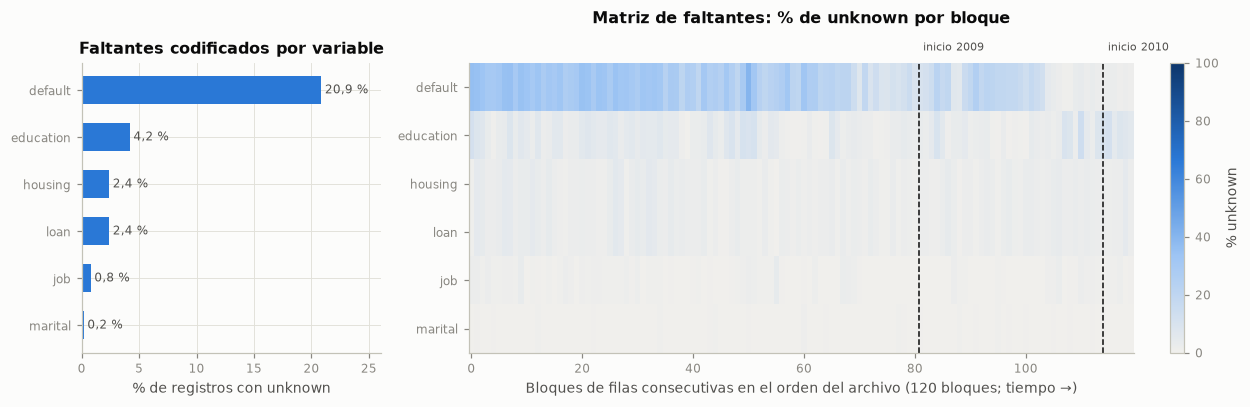

,unknown (n),unknown (%)
default,8 597,"20,87"
education,1 731,"4,20"
housing,990,"2,40"
loan,990,"2,40"
job,330,"0,80"
marital,80,"0,19"


,registros,% que suscribe,% de registros
Variables con unknown,,,
ninguno,30 488,"12,66","74,02"
default,7 757,"5,14","18,83"
education,1 102,"18,42","2,68"
housing + loan,739,"12,31","1,79"
education + default,456,"5,70","1,11"
default + housing + loan,207,"5,31","0,50"
job,116,"14,66","0,28"
job + default,76,"2,63","0,18"


**Interpretación.** `default` concentra la mayor proporción de faltantes (20,9 %), seguida de `education` (4,2 %); en total, el 26,0 % de los registros tiene al menos un `unknown`. La matriz muestra que los faltantes de `default` no se reparten de forma uniforme en el tiempo. Además, `housing` y `loan` son unknown exactamente en los mismos registros.

En ese sentido, eliminar los registros incompletos descartaría el 26,0 % de la muestra; y como el faltante cambia a lo largo del archivo, su presencia puede estar ligada al periodo de la campaña.

Por esta razón, lo indicado es evaluar el mecanismo de faltantes (sección 1.6.2) antes de decidir el tratamiento y no eliminar filas.

In [6]:
print(f"Nulos explícitos (NaN) en todo el archivo: {int(df.isna().sum().sum())}")
CON_UNKNOWN = [c for c in CATEGORICAS if (df[c] == "unknown").any()]
U = df[CON_UNKNOWN].eq("unknown")
faltantes = pd.DataFrame({"unknown (n)": U.sum(), "unknown (%)": 100 * U.mean()}).sort_values("unknown (n)",
                                                                                           ascending=False)
alguno = U.any(axis=1)

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8), gridspec_kw={"width_ratios": [1, 2.4]})
ax[0].barh(faltantes.index[::-1], faltantes["unknown (%)"][::-1], color=AZUL, height=0.6)
for i, v in enumerate(faltantes["unknown (%)"][::-1]):
    ax[0].text(v + 0.3, i, f"{num(v, 1)} %", va="center", fontsize=8, color=TINTA_2)
ax[0].set_xlabel("% de registros con unknown")
ax[0].set_title("Faltantes codificados por variable")
ax[0].set_xlim(0, faltantes["unknown (%)"].max() * 1.25)
# Matriz de faltantes: % de unknown por bloque de filas consecutivas (orden cronológico del archivo)
n_bloq = 120
bloque = np.arange(len(df)) * n_bloq // len(df)
matriz = U.groupby(bloque).mean().T.loc[faltantes.index]
im = ax[1].imshow(100 * matriz.to_numpy(), aspect="auto", cmap=CMAP_SEQ, vmin=0, vmax=100,
                  interpolation="nearest")
ax[1].set_yticks(range(len(matriz)), matriz.index)
for pos in np.flatnonzero(np.diff(tiempo["anio"].to_numpy()) > 0):
    ax[1].axvline(pos * n_bloq / len(df), color=TINTA, lw=1, ls="--")
    ax[1].text(pos * n_bloq / len(df) + 0.8, -0.7, f"inicio {tiempo['anio'].iloc[pos + 1]}", fontsize=7.5,
               color=TINTA_2, va="bottom")
ax[1].set_xlabel(f"Bloques de filas consecutivas en el orden del archivo ({n_bloq} bloques; tiempo →)")
ax[1].set_title("Matriz de faltantes: % de unknown por bloque", pad=26)
ax[1].grid(False)
fig.colorbar(im, ax=ax[1], fraction=0.025, label="% unknown")
plt.tight_layout()
plt.show()

tabla(faltantes, dec=2)

# Patrones conjuntos de faltantes
patron = U.apply(lambda r: " + ".join(c for c in CON_UNKNOWN if r[c]) or "ninguno", axis=1)
patrones = (pd.DataFrame({"patron": patron, "yes": df[OBJETIVO].eq("yes")})
            .groupby("patron").agg(registros=("yes", "size"), tasa_yes=("yes", "mean"))
            .sort_values("registros", ascending=False))
patrones["% de registros"] = 100 * patrones["registros"] / len(df)
patrones["tasa_yes"] = 100 * patrones["tasa_yes"]
tabla(patrones.head(8).rename(columns={"tasa_yes": "% que suscribe"}).rename_axis("Variables con unknown"), dec=2)

hl_iguales = int((U["housing"] == U["loan"]).all())
top = faltantes.index[0]
interpretar(
    f"`{top}` concentra la mayor proporción de faltantes ({num(faltantes.loc[top, 'unknown (%)'], 1)} %), seguida de "
    f"`{faltantes.index[1]}` ({num(faltantes.iloc[1, 1], 1)} %); en total, el {pct(alguno.mean())} de los registros "
    f"tiene al menos un `unknown`. La matriz muestra que los faltantes de `{top}` no se reparten de forma uniforme "
    f"en el tiempo. Además, `housing` y `loan` {'son unknown exactamente en los mismos registros' if hl_iguales else 'no coinciden siempre en sus faltantes'}.",
    f"En ese sentido, eliminar los registros incompletos descartaría el {pct(alguno.mean())} de la muestra; y como el "
    "faltante cambia a lo largo del archivo, su presencia puede estar ligada al periodo de la campaña.",
    "Por esta razón, lo indicado es evaluar el mecanismo de faltantes (sección 1.6.2) antes de decidir el tratamiento "
    "y no eliminar filas.")

### 1.6.2 Valores faltantes: mecanismo

No se aplica la prueba de Little porque supone variables numéricas con normalidad multivariada y aquí los faltantes son categóricos. Se usa la alternativa que acepta el enunciado: **comparar registros con y sin `unknown`** en la tasa de la variable objetivo y en la distribución de variables observadas (edad, canal de contacto y año). Si los faltantes fueran MCAR (completamente al azar), ambos grupos tendrían distribuciones similares. Las pruebas son χ² para proporciones y Mann-Whitney para la edad, con corrección de Holm por comparaciones múltiples y tamaño de efecto (V de Cramér).

In [7]:
def v_cramer(tabla_cont):
    chi2, p, _, _ = stats.chi2_contingency(tabla_cont, correction=False)
    n = tabla_cont.to_numpy().sum()
    k = min(tabla_cont.shape) - 1
    return np.sqrt(chi2 / (n * k)) if k > 0 else np.nan, chi2, p


yes = df[OBJETIVO].eq("yes")
filas_mec = []
indicadores = {**{c: U[c] for c in CON_UNKNOWN}, "alguno (registro incompleto)": alguno}
for nombre, falta in indicadores.items():
    v_y, _, p_y = v_cramer(pd.crosstab(falta, yes))
    _, p_edad = stats.mannwhitneyu(df.loc[falta, "age"], df.loc[~falta, "age"])
    v_anio, _, p_anio = v_cramer(pd.crosstab(falta, tiempo["anio"]))
    v_canal, _, p_canal = v_cramer(pd.crosstab(falta, df["contact"]))
    filas_mec.append({
        "Variable": nombre, "n unknown": int(falta.sum()),
        "% suscribe con unknown": 100 * yes[falta].mean(), "% suscribe sin unknown": 100 * yes[~falta].mean(),
        "p χ² (y)": p_y, "V (y)": v_y,
        "Edad mediana con unknown": df.loc[falta, "age"].median(), "Edad mediana sin unknown": df.loc[~falta, "age"].median(),
        "p Mann-Whitney (edad)": p_edad,
        "% de 2008 con unknown": 100 * (tiempo.loc[falta, "anio"] == 2008).mean(),
        "% de 2008 sin unknown": 100 * (tiempo.loc[~falta, "anio"] == 2008).mean(),
        "V (año)": v_anio, "p χ² (año)": p_anio, "V (canal)": v_canal, "p χ² (canal)": p_canal})
mecanismo = pd.DataFrame(filas_mec).set_index("Variable")
for col in ["p χ² (y)", "p Mann-Whitney (edad)", "p χ² (año)", "p χ² (canal)"]:
    mecanismo[col] = multipletests(mecanismo[col], method="holm")[1]
tabla(mecanismo, dec=3)
print("Valores p ajustados por Holm dentro de cada familia de pruebas (columna).")

sig_y = mecanismo.index[mecanismo["p χ² (y)"] < 0.05].tolist()
sig_alguna = (mecanismo[["p χ² (y)", "p Mann-Whitney (edad)", "p χ² (año)", "p χ² (canal)"]] < 0.05).any(axis=1)
sin_asociacion = [v for v in CON_UNKNOWN if not sig_alguna[v]]
d = mecanismo.loc["default"]
inc = mecanismo.loc["alguno (registro incompleto)"]
interpretar(
    f"La tasa de suscripción difiere entre registros con y sin `unknown` en {len(sig_y)} de las "
    f"{len(mecanismo)} comparaciones (p de Holm < 0,05). En `default`, que concentra la mayoría de faltantes, "
    f"suscribe el {num(d['% suscribe con unknown'], 1)} % de los registros con `unknown` frente al "
    f"{num(d['% suscribe sin unknown'], 1)} % de los demás (V = {num(d['V (y)'], 3)}); la edad mediana es "
    f"{num(d['Edad mediana con unknown'])} frente a {num(d['Edad mediana sin unknown'])} años y el "
    f"{num(d['% de 2008 con unknown'], 1)} % de sus faltantes es de 2008, frente al "
    f"{num(d['% de 2008 sin unknown'], 1)} % entre los registros completos. Los registros incompletos en conjunto "
    f"suscriben el {num(inc['% suscribe con unknown'], 1)} % frente al {num(inc['% suscribe sin unknown'], 1)} %.",
    "De esta forma, la evidencia descarta MCAR para "
    + (f"todas las variables salvo {enumerar(sin_asociacion)}" if sin_asociacion else "todas las variables")
    + ": los faltantes se asocian con variables observadas (edad, año o canal), lo que es compatible con MAR, y en "
    + enumerar([v for v in sig_y if v in CON_UNKNOWN])
    + " también con la variable objetivo. MNAR no se puede descartar con los datos (por ejemplo, "
    f"un cliente con problemas de crédito puede preferir no declararlo). El mayor tamaño de efecto frente a `y` es "
    f"V = {num(mecanismo['V (y)'].max(), 3)}, así que la asociación es estadísticamente clara pero de magnitud "
    "modesta. En cualquier caso, el `unknown` es **informativo**.",
    "De ahí que se opte por no eliminar registros ni imputar la moda, porque ambas opciones borran una señal asociada "
    "al resultado, y por tratar `unknown` como una categoría explícita dentro del codificador (sección 3.7).")

,n unknown,% suscribe con unknown,% suscribe sin unknown,p χ² (y),V (y),Edad mediana con unknown,Edad mediana sin unknown,p Mann-Whitney (edad),% de 2008 con unknown,% de 2008 sin unknown,V (año),p χ² (año),V (canal),p χ² (canal)
Variable,,,,,,,,,,,,,,
job,330,"11,212","11,266","1,000","0,000","45,000","38,000","0,000","75,152","67,164","0,017","0,012","0,023","0,000"
marital,80,"15,000","11,258","1,000","0,005","35,500","38,000","1,000","58,750","67,245","0,010","0,441","0,003","0,606"
education,1 731,"14,500","11,124","0,000","0,021","43,000","38,000","0,000","66,147","67,276","0,043","0,000","0,021","0,000"
default,8 597,"5,153","12,878","0,000","0,099","43,000","37,000","0,000","83,506","62,935","0,185","0,000","0,136","0,000"
housing,990,"10,808","11,277","1,000","0,002","38,000","38,000","1,000","67,778","67,215","0,003","1,000","0,022","0,000"
loan,990,"10,808","11,277","1,000","0,002","38,000","38,000","1,000","67,778","67,215","0,003","1,000","0,022","0,000"
alguno (registro incompleto),10 700,"7,299","12,657","0,000","0,074","42,000","37,000","0,000","78,551","63,254","0,145","0,000","0,125","0,000"


Valores p ajustados por Holm dentro de cada familia de pruebas (columna).


**Interpretación.** La tasa de suscripción difiere entre registros con y sin `unknown` en 3 de las 7 comparaciones (p de Holm < 0,05). En `default`, que concentra la mayoría de faltantes, suscribe el 5,2 % de los registros con `unknown` frente al 12,9 % de los demás (V = 0,099); la edad mediana es 43 frente a 37 años y el 83,5 % de sus faltantes es de 2008, frente al 62,9 % entre los registros completos. Los registros incompletos en conjunto suscriben el 7,3 % frente al 12,7 %.

De esta forma, la evidencia descarta MCAR para todas las variables salvo `marital`: los faltantes se asocian con variables observadas (edad, año o canal), lo que es compatible con MAR, y en `education` y `default` también con la variable objetivo. MNAR no se puede descartar con los datos (por ejemplo, un cliente con problemas de crédito puede preferir no declararlo). El mayor tamaño de efecto frente a `y` es V = 0,099, así que la asociación es estadísticamente clara pero de magnitud modesta. En cualquier caso, el `unknown` es **informativo**.

De ahí que se opte por no eliminar registros ni imputar la moda, porque ambas opciones borran una señal asociada al resultado, y por tratar `unknown` como una categoría explícita dentro del codificador (sección 3.7).

### 1.6.3 Duplicados exactos y casi duplicados

Se distinguen dos niveles: **duplicados exactos** (las 21 columnas idénticas) y **casi duplicados** (las 19 predictoras distintas de `duration` idénticas). Como no hay identificador de cliente, un casi duplicado puede ser un error de registro o dos clientes distintos con el mismo perfil contactados en el mismo periodo.

In [8]:
n_dup_exactos = int(df.duplicated().sum())
PRED_SIN_DUR = [c for c in NUMERICAS + CATEGORICAS if c != "duration"]
casi = df.duplicated(subset=PRED_SIN_DUR, keep=False)
grupos_casi = df[casi].groupby(PRED_SIN_DUR)[OBJETIVO].agg(["size", "nunique"])
n_grupos = len(grupos_casi)
n_conflicto = int((grupos_casi["nunique"] > 1).sum())
filas_conflicto = int(grupos_casi.loc[grupos_casi["nunique"] > 1, "size"].sum())

duplicados = pd.DataFrame({"Valor": [n_dup_exactos, int(casi.sum()), n_grupos, n_conflicto, filas_conflicto]},
                          index=["Duplicados exactos (filas sobrantes)",
                                 "Filas en grupos de casi duplicados (predictoras sin duration idénticas)",
                                 "Grupos de casi duplicados", "Grupos con etiquetas y contradictorias",
                                 "Filas en grupos con etiquetas contradictorias"])
tabla(duplicados)
print("Ejemplo de duplicados exactos (primeras filas):")
display(df[df.duplicated(keep=False)].sort_values(PRED_SIN_DUR).head(6))

interpretar(
    f"Hay {n_dup_exactos} duplicados exactos (incluso la duración en segundos coincide) y {num(int(casi.sum()))} "
    f"filas ({pct(casi.mean())}) que comparten todas las predictoras salvo `duration`, en {num(n_grupos)} grupos. En "
    f"{num(n_conflicto)} de esos grupos la etiqueta `y` es contradictoria ({num(filas_conflicto)} filas).",
    "Lo anterior indica que los duplicados exactos son, con alta probabilidad, errores de registro y, si cayeran en "
    "entrenamiento y prueba a la vez, inflarían la evaluación. Los casi duplicados con etiquetas contradictorias "
    "indican **ruido irreducible**: con estas predictoras hay perfiles idénticos que a veces suscriben y a veces no, "
    "lo que pone un techo al desempeño alcanzable.",
    "Por ello, se procede a eliminar los duplicados exactos antes de la partición (sección 2), conservar los casi "
    "duplicados (no hay evidencia de que sean errores) y verificar cuántos quedan repartidos entre entrenamiento y "
    "prueba en la auditoría de fuga (sección 3.5).")

,Valor
Duplicados exactos (filas sobrantes),12
Filas en grupos de casi duplicados (predictoras sin duration idénticas),3 731
Grupos de casi duplicados,1 710
Grupos con etiquetas y contradictorias,237
Filas en grupos con etiquetas contradictorias,542


Ejemplo de duplicados exactos (primeras filas):


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
28476,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
28477,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no


**Interpretación.** Hay 12 duplicados exactos (incluso la duración en segundos coincide) y 3 731 filas (9,1 %) que comparten todas las predictoras salvo `duration`, en 1 710 grupos. En 237 de esos grupos la etiqueta `y` es contradictoria (542 filas).

Lo anterior indica que los duplicados exactos son, con alta probabilidad, errores de registro y, si cayeran en entrenamiento y prueba a la vez, inflarían la evaluación. Los casi duplicados con etiquetas contradictorias indican **ruido irreducible**: con estas predictoras hay perfiles idénticos que a veces suscriben y a veces no, lo que pone un techo al desempeño alcanzable.

Por ello, se procede a eliminar los duplicados exactos antes de la partición (sección 2), conservar los casi duplicados (no hay evidencia de que sean errores) y verificar cuántos quedan repartidos entre entrenamiento y prueba en la auditoría de fuga (sección 3.5).

### 1.6.4 Valores imposibles, códigos especiales e inconsistencias

Se revisan los rangos de las numéricas, las categorías frente a las documentadas y la coherencia lógica entre las variables de campañas anteriores (`pdays`, `previous`, `poutcome`).

In [9]:
DOCUMENTADAS = {
    "job": {"admin.", "blue-collar", "entrepreneur", "housemaid", "management", "retired", "self-employed",
            "services", "student", "technician", "unemployed", "unknown"},
    "marital": {"divorced", "married", "single", "unknown"},
    "education": {"basic.4y", "basic.6y", "basic.9y", "high.school", "illiterate", "professional.course",
                  "university.degree", "unknown"},
    "default": {"no", "yes", "unknown"}, "housing": {"no", "yes", "unknown"}, "loan": {"no", "yes", "unknown"},
    "contact": {"cellular", "telephone"}, "month": set(ORDEN_MESES),
    "day_of_week": {"mon", "tue", "wed", "thu", "fri"}, "poutcome": {"failure", "nonexistent", "success"},
}
no_documentadas = {c: sorted(set(df[c].unique()) - DOCUMENTADAS[c]) for c in CATEGORICAS}
espacios = sum(int((df[c] != df[c].str.strip()).sum()) for c in CATEGORICAS)
print("Categorías fuera de la documentación:", {c: v for c, v in no_documentadas.items() if v} or "ninguna")
print(f"Valores categóricos con espacios sobrantes: {espacios}")
print("Meses ausentes en todo el archivo:", sorted(set(ORDEN_MESES) - set(df["month"].unique()),
                                                 key=ORDEN_MESES.index))

rangos = df[NUMERICAS].agg(["min", "max"]).T
rangos.columns = ["Mínimo", "Máximo"]
tabla(rangos, dec=3)

reglas = {
    "age < 18 (menor de edad)": df["age"] < 18,
    "duration = 0": df["duration"] == 0,
    "duration = 0 y y = yes (contradicción lógica)": (df["duration"] == 0) & yes,
    "pdays = 999 (código: sin contacto previo)": df["pdays"] == 999,
    "pdays = 999 y previous > 0 (inconsistente con el código)": (df["pdays"] == 999) & (df["previous"] > 0),
    "pdays ≠ 999 y previous = 0": (df["pdays"] != 999) & (df["previous"] == 0),
    "poutcome = nonexistent y previous > 0": (df["poutcome"] == "nonexistent") & (df["previous"] > 0),
    "poutcome ≠ nonexistent y previous = 0": (df["poutcome"] != "nonexistent") & (df["previous"] == 0),
}
chequeos = pd.DataFrame({"Registros": {k: int(v.sum()) for k, v in reglas.items()}})
chequeos["%"] = 100 * chequeos["Registros"] / len(df)
tabla(chequeos, dec=2)
print("poutcome de los registros con pdays = 999 y previous > 0:")
print(df.loc[reglas["pdays = 999 y previous > 0 (inconsistente con el código)"], "poutcome"].value_counts().to_dict())

inc_pdays = chequeos.loc["pdays = 999 y previous > 0 (inconsistente con el código)", "Registros"]
sin_errores_cat = not any(no_documentadas.values()) and espacios == 0
dur0_ok = chequeos.loc["duration = 0 y y = yes (contradicción lógica)", "Registros"] == 0
interpretar(
    ("No hay categorías fuera de las documentadas ni errores de escritura" if sin_errores_cat
     else "Hay categorías fuera de la documentación o con espacios sobrantes")
    + f", y los rangos numéricos son plausibles "
    f"(edad entre {df['age'].min()} y {df['age'].max()} años; {int(reglas['age < 18 (menor de edad)'].sum())} "
    f"registros de menores de 18). El código `pdays = 999` aparece en el "
    f"{pct(reglas['pdays = 999 (código: sin contacto previo)'].mean())} de los registros y es un valor especial, no "
    f"una cantidad de días. Hay una inconsistencia: {num(inc_pdays)} registros tienen `pdays = 999` (\"sin contacto "
    f"previo\") pero `previous > 0` y `poutcome = failure`. Los {int(reglas['duration = 0'].sum())} registros con "
    f"`duration = 0` " + ("tienen todos `y = no`." if dur0_ok else "no siempre tienen `y = no`."),
    "Por consiguiente, si `pdays` entra como número, el modelo trataría 999 días como una distancia real y la relación "
    "quedaría distorsionada. La inconsistencia sugiere que 999 significa en realidad \"sin registro de días\" y no "
    "\"nunca contactado\"; la información de contacto previo la aportan mejor `previous` y `poutcome`. La regla "
    "`duration = 0` ⇒ `y = no` confirma que `duration` contiene información del resultado.",
    "Con base en esto, se propone convertir `pdays = 999` en faltante con un indicador explícito dentro del `Pipeline` "
    "(sección 3.7), conservar `previous` y `poutcome` y no corregir manualmente la inconsistencia (no hay forma de "
    "saber el valor real).")

Categorías fuera de la documentación: ninguna
Valores categóricos con espacios sobrantes: 0
Meses ausentes en todo el archivo: ['jan', 'feb']


,Mínimo,Máximo
age,"17,000","98,000"
duration,"0,000","4 918,000"
campaign,"1,000","56,000"
pdays,"0,000","999,000"
previous,"0,000","7,000"
emp.var.rate,"-3,400","1,400"
cons.price.idx,"92,201","94,767"
cons.conf.idx,"-50,800","-26,900"
euribor3m,"0,634","5,045"
nr.employed,"4 963,600","5 228,100"


,Registros,%
age < 18 (menor de edad),5,"0,01"
duration = 0,4,"0,01"
duration = 0 y y = yes (contradicción lógica),0,"0,00"
pdays = 999 (código: sin contacto previo),39 673,"96,32"
pdays = 999 y previous > 0 (inconsistente con el código),4 110,"9,98"
pdays ≠ 999 y previous = 0,0,"0,00"
poutcome = nonexistent y previous > 0,0,"0,00"
poutcome ≠ nonexistent y previous = 0,0,"0,00"


poutcome de los registros con pdays = 999 y previous > 0:
{'failure': 4110}


**Interpretación.** No hay categorías fuera de las documentadas ni errores de escritura, y los rangos numéricos son plausibles (edad entre 17 y 98 años; 5 registros de menores de 18). El código `pdays = 999` aparece en el 96,3 % de los registros y es un valor especial, no una cantidad de días. Hay una inconsistencia: 4 110 registros tienen `pdays = 999` ("sin contacto previo") pero `previous > 0` y `poutcome = failure`. Los 4 registros con `duration = 0` tienen todos `y = no`.

Por consiguiente, si `pdays` entra como número, el modelo trataría 999 días como una distancia real y la relación quedaría distorsionada. La inconsistencia sugiere que 999 significa en realidad "sin registro de días" y no "nunca contactado"; la información de contacto previo la aportan mejor `previous` y `poutcome`. La regla `duration = 0` ⇒ `y = no` confirma que `duration` contiene información del resultado.

Con base en esto, se propone convertir `pdays = 999` en faltante con un indicador explícito dentro del `Pipeline` (sección 3.7), conservar `previous` y `poutcome` y no corregir manualmente la inconsistencia (no hay forma de saber el valor real).

### 1.6.5 Valores atípicos (inventario)

Se aplica la regla de Tukey (fuera de $[Q_1 - 1{,}5\,\mathrm{IQR},\; Q_3 + 1{,}5\,\mathrm{IQR}]$) a cada variable numérica. Este inventario solo cuantifica; la decisión de tratamiento se toma con el conjunto de entrenamiento (secciones 3.2 y 3.4).

In [10]:
filas_iqr = []
for c in NUMERICAS:
    s = df[c]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    fuera = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)
    filas_iqr.append({"Variable": c, "Q1": q1, "Q3": q3, "IQR": iqr, "Límite inferior": q1 - 1.5 * iqr,
                      "Límite superior": q3 + 1.5 * iqr, "Atípicos (n)": int(fuera.sum()), "Atípicos (%)": 100 * fuera.mean()})
inventario_iqr = pd.DataFrame(filas_iqr).set_index("Variable")
tabla(inventario_iqr, dec=2)

con_atip = inventario_iqr[inventario_iqr["Atípicos (n)"] > 0].sort_values("Atípicos (%)", ascending=False)
interpretar(
    f"{len(con_atip)} de las {len(NUMERICAS)} numéricas tienen valores fuera de los límites de Tukey: "
    + ", ".join(f"`{i}` ({num(r['Atípicos (%)'], 1)} %)" for i, r in con_atip.iterrows())
    + ". En `pdays` y `previous` el IQR es cero porque la gran mayoría de los valores es igual (999 y 0), así que "
      "cualquier valor distinto aparece como atípico.",
    "Entonces, estos valores son plausibles (llamadas largas, clientes contactados muchas veces, clientes con "
    "historial), no errores; eliminarlos quitaría precisamente a los clientes con historial previo, que son "
    "informativos. Sí pueden ejercer palanca en un modelo lineal cuando la distribución tiene cola larga.",
    "Así las cosas, la decisión es no eliminar atípicos, sino reducir su influencia con transformaciones (sección 3.2) "
    "y revisar los atípicos multivariados en la sección 3.4.")

,Q1,Q3,IQR,Límite inferior,Límite superior,Atípicos (n),Atípicos (%)
Variable,,,,,,,
age,"32,00","47,00","15,00","9,50","69,50",469,"1,14"
duration,"102,00","319,00","217,00","-223,50","644,50",2 963,"7,19"
campaign,"1,00","3,00","2,00","-2,00","6,00",2 406,"5,84"
pdays,"999,00","999,00","0,00","999,00","999,00",1 515,"3,68"
previous,"0,00","0,00","0,00","0,00","0,00",5 625,"13,66"
emp.var.rate,"-1,80","1,40","3,20","-6,60","6,20",0,"0,00"
cons.price.idx,"93,08","93,99","0,92","91,70","95,37",0,"0,00"
cons.conf.idx,"-42,70","-36,40","6,30","-52,15","-26,95",447,"1,09"
euribor3m,"1,34","4,96","3,62","-4,08","10,39",0,"0,00"


**Interpretación.** 6 de las 10 numéricas tienen valores fuera de los límites de Tukey: `previous` (13,7 %), `duration` (7,2 %), `campaign` (5,8 %), `pdays` (3,7 %), `age` (1,1 %), `cons.conf.idx` (1,1 %). En `pdays` y `previous` el IQR es cero porque la gran mayoría de los valores es igual (999 y 0), así que cualquier valor distinto aparece como atípico.

Entonces, estos valores son plausibles (llamadas largas, clientes contactados muchas veces, clientes con historial), no errores; eliminarlos quitaría precisamente a los clientes con historial previo, que son informativos. Sí pueden ejercer palanca en un modelo lineal cuando la distribución tiene cola larga.

Así las cosas, la decisión es no eliminar atípicos, sino reducir su influencia con transformaciones (sección 3.2) y revisar los atípicos multivariados en la sección 3.4.

### 1.6.6 Sesgos de muestreo y representatividad

- **Población:** los registros corresponden a clientes que **el banco eligió contactar** en sus campañas, no a una muestra aleatoria de la población ni de todos los clientes. El modelo solo es válido para esa población objetivo.
- **Una sola institución y un solo país:** los resultados no se pueden generalizar a otros bancos, productos o mercados sin validación.
- **Periodo atípico:** el archivo cubre de mayo de 2008 a noviembre de 2010, en plena crisis financiera, con la tasa Euribor en caída (sección 3.6); las relaciones aprendidas pueden no sostenerse en otros contextos económicos.
- **Volumen desigual en el tiempo:** la tabla de la sección 1.5 muestra que el primer año concentra la mayor parte de los registros, de modo que el modelo aprende sobre todo del comportamiento de ese año.
- **Atributos recortados:** la documentación señala que el archivo no incluye todos los atributos del estudio original por razones de privacidad, así que el desempeño no es comparable de forma directa con el del artículo de referencia.

## 1.7 Consideraciones éticas

- **Datos personales y anonimización:** el archivo no contiene nombres, documentos, teléfonos ni identificadores de cliente; las fechas solo tienen mes y día de la semana, sin año ni día exacto, y no hay coordenadas. El riesgo de reidentificación es bajo, aunque la combinación de edad, ocupación, estado civil, educación y situación crediticia podría singularizar a personas dentro del propio banco.
- **Información sensible:** `default`, `housing` y `loan` describen la situación financiera del cliente; su uso debe limitarse al propósito declarado.
- **Equidad:** un modelo que prioriza llamadas según edad, estado civil u ocupación puede concentrar la presión comercial en grupos específicos (por ejemplo, personas jubiladas). Cualquier despliegue debería auditar el efecto por grupos.
- **Licencia:** CC BY 4.0 exige atribución, que se cumple con las citas de la sección 6.